# 이중 하강 (Double Descent) 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/ml1/week15/2_double_descent/lab/double_descent.ipynb)

계수가 데이터보다 많아서 학습 데이터를 완벽히 외우는 모델이 왜 다시 좋아지는지 직접 재현한다.

- **파트 1**: 제동거리 점 10개: 최소 노름 해 구현 → 9차 9.1 m · 16차 3.9 m, 경사하강법도 같은 해로 가나
- **파트 2**: 손글씨 숫자 200장: 무작위 ReLU 특징으로 이중 하강 곡선 그리기
- **파트 3**: 라벨 잡음 · 릿지 λ · 학습 데이터 수로 피크를 키우고 없애기

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial import legendre

## 파트 1. 제동거리 점 10개와 최소 노름 해

2주차와 같은 데이터. 다항식은 르장드르 기저로 쓴다 (속도를 $(v - 55) / 50$ 으로 $[-1, 1]$ 에 맞춤). 계수가 점보다 많으면 모든 점을 지나는 해가 무수히 많고, 그중 크기가 가장 작은 해는

$$w^{*} = X^\top (X X^\top)^{-1} y$$

In [ ]:
speed = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100], dtype=float)     # km/h
dist = np.array([2, 7, 0, 14, 14, 18, 25, 33, 45, 59], dtype=float)            # measured braking distance (m)
speed_new = np.array([15, 35, 45, 65, 85, 95], dtype=float)
dist_new = np.array([3, 9, 6, 19, 45, 54], dtype=float)

def design(v, d):
    return legendre.legvander((v - 55) / 50, d)          # columns = Legendre polynomials of degree 0..d

def min_norm(X, y):
    return None  # TODO: X^T (X X^T)^-1 y  (use np.linalg.solve)

def mae(X, w, y):
    return np.abs(X @ w - y).mean()

for d in [9, 16]:
    w = min_norm(design(speed, d), dist)
    w_lstsq, *_ = np.linalg.lstsq(design(speed, d), dist, rcond=None)
    print(f"degree {d:2d}: train MAE {mae(design(speed, d), w, dist):.1f} m   new-data MAE {mae(design(speed_new, d), w, dist_new):.1f} m"
          f"   |w| = {np.linalg.norm(w):.1f}   same as lstsq: {np.allclose(w, w_lstsq)}")

**예상 결과**

```
degree  9: train MAE 0.0 m   new-data MAE 9.1 m   |w| = 130.0   same as lstsq: True
degree 16: train MAE 0.0 m   new-data MAE 3.9 m   |w| = 38.6   same as lstsq: True
```

In [ ]:
# All degrees 1..20. np.linalg.lstsq gives the ordinary least-squares fit below degree 9 and the minimum-norm fit above.
def sweep_degrees(x, y, x_new, y_new, degrees):
    out = {}
    for d in degrees:
        w, *_ = np.linalg.lstsq(design(x, d), y, rcond=None)
        out[d] = (mae(design(x_new, d), w, y_new), np.linalg.norm(w))
    return out

res = sweep_degrees(speed, dist, speed_new, dist_new, range(1, 21))
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(list(res), [e for e, _ in res.values()], "^-r"); axs[0].set_title("new-data error (m)")
axs[1].plot(list(res), [n for _, n in res.values()], "o-", color="goldenrod"); axs[1].set_title("|w|")
for ax in axs:
    ax.axvline(9, color="gray", ls="--"); ax.set_xlabel("degree")
plt.show()
print({d: round(float(e), 1) for d, (e, _) in res.items()})

**예상 결과**

```
{1: 6.4, 2: 3.1, 3: 2.9, 4: 3.2, 5: 3.2, 6: 3.4, 7: 5.0, 8: 7.3, 9: 9.1, 10: 9.0, 11: 5.9, 12: 5.9, 13: 4.5, 14: 4.6, 15: 4.7, 16: 3.9, 17: 5.2, 18: 5.1, 19: 5.0, 20: 5.1}
```

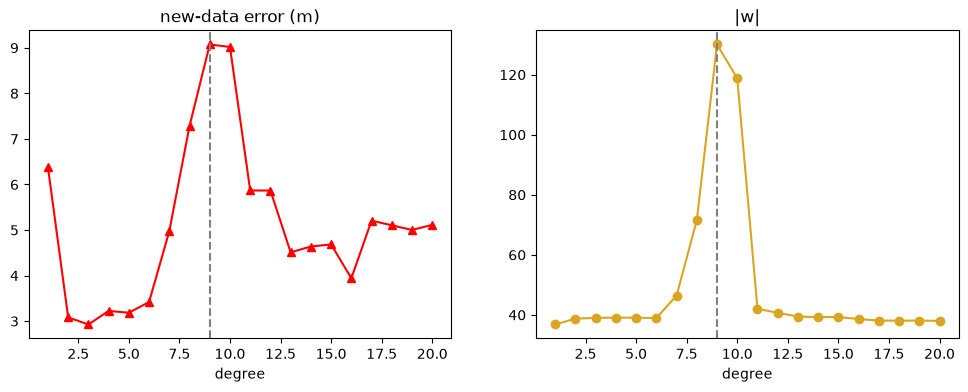

### 경사하강법은 어디에 도착하나

$w \leftarrow w - \eta X^\top (Xw - y)$ 를 16차에서 1000번. 출발점을 모두 0 으로 할 때와 모두 3 으로 할 때를 비교한다. 학습률은 $\eta = 1 / \sigma_{\max}^2$ ($X$ 의 가장 큰 특잇값).

In [ ]:
def gradient_descent(X, y, w0, steps):
    lr = 1 / np.linalg.norm(X, 2) ** 2
    w = w0.copy()
    for _ in range(steps):
        w = None  # TODO: one gradient step on 0.5 * ||Xw - y||^2
    return w

X16 = design(speed, 16)
w_star = min_norm(X16, dist)
for start in [0.0, 3.0]:
    w = gradient_descent(X16, dist, np.full(17, start), 1000)
    print(f"start {start}: max train residual {np.abs(X16 @ w - dist).max():.3f}   distance to min-norm {np.linalg.norm(w - w_star):.1f}"
          f"   new-data MAE {mae(design(speed_new, 16), w, dist_new):.2f} m")

**예상 결과**

```
start 0.0: max train residual 0.000   distance to min-norm 0.0   new-data MAE 3.94 m
start 3.0: max train residual 0.000   distance to min-norm 11.6   new-data MAE 3.82 m
```

## 파트 2. 손글씨 숫자로 이중 하강

UCI optdigits: 8×8 = 64칸, 밝기 0~16. 학습 = 앞에서부터 200장, 시험 = 따로 마련된 1797장.

모델: $h(x) = \sum_{j=1}^{p} w_j \, \mathrm{ReLU}(a_j^\top x)$. 첫 층 $a_j$ 는 무작위로 정하고 고정, $w$ 만 최소제곱 (최소 노름) 으로 학습. 정답은 원-핫 10칸, 예측은 가장 큰 칸.

In [ ]:
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/optdigits/"

def load_optdigits(folder="data"):
    os.makedirs(folder, exist_ok=True)
    arrays = []
    for name in ["optdigits.tra", "optdigits.tes"]:
        path = os.path.join(folder, name)
        if not os.path.exists(path):
            urllib.request.urlretrieve(URL + name, path)
        a = np.loadtxt(path, delimiter=",")
        arrays += [a[:, :64] / 16, a[:, 64].astype(int)]
    return arrays

X_train, y_train, X_test, y_test = load_optdigits()
print(X_train.shape, X_test.shape)
fig, axs = plt.subplots(1, 10, figsize=(12, 1.6))
for k, ax in enumerate(axs):
    ax.imshow(X_train[k].reshape(8, 8), cmap="gray_r"); ax.set_title(y_train[k]); ax.axis("off")
plt.show()

**예상 결과**

```
(3823, 64) (1797, 64)
```

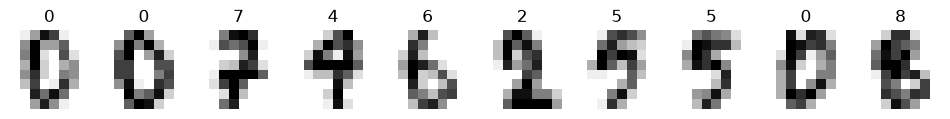

In [ ]:
N = 200            # training images
P_MAX = 4000       # largest number of random features
SEEDS = range(5)

def relu_features(X, A):
    return None  # TODO: ReLU(X A)

def test_error(X, y, X_t, y_t, n, p, seed, lam=0.0, noisy=False):
    """Train on the first n images with p random ReLU features. Returns (test error %, |w|)."""
    A = np.random.default_rng(seed).normal(size=(64, P_MAX))[:, :p] / 8   # fixed random first layer
    mu = X[:n].mean(axis=0)                                                # center inputs (avoids dead features)
    F, F_t = relu_features(X[:n] - mu, A), relu_features(X_t - mu, A)
    labels = y[:n].copy()
    if noisy:
        labels[::5] = (labels[::5] + 1) % 10            # every 5th image gets the next digit as its label (20%)
    Y = np.eye(10)[labels]                              # one-hot targets
    if lam > 0:
        w = F.T @ np.linalg.solve(F @ F.T + lam * np.eye(n), Y)      # ridge (dual form)
    else:
        w, *_ = np.linalg.lstsq(F, Y, rcond=None)                    # least squares / minimum norm
    err = None  # TODO: % of test images whose largest output is not the true digit
    return err, np.linalg.norm(w)

print("p = 100, seed 0: error %.1f%%, |w| = %.1f" % test_error(X_train, y_train, X_test, y_test, N, 100, 0))

**예상 결과**

```
p = 100, seed 0: error 20.9%, |w| = 9.0
```

In [ ]:
PS = [10, 20, 50, 100, 150, 180, 200, 220, 250, 300, 400, 600, 1000, 2000, 4000]

def sweep_features(data, ps, n, **kw):
    return {p: np.mean([test_error(*data, n, p, s, **kw) for s in SEEDS], axis=0) for p in ps}

data = (X_train, y_train, X_test, y_test)
clean = sweep_features(data, PS, N)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(PS, [clean[p][0] for p in PS], "o-"); axs[0].set_ylabel("test error (%)")
axs[1].plot(PS, [clean[p][1] for p in PS], "o-", color="goldenrod"); axs[1].set_yscale("log"); axs[1].set_ylabel("|w|")
for ax in axs:
    ax.set_xscale("log"); ax.axvline(N, color="gray", ls="--"); ax.set_xlabel("number of features p")
plt.show()
print({p: round(float(clean[p][0])) for p in [100, 200, 4000]})

**예상 결과**

```
{100: 20, 200: 83, 4000: 10}
```

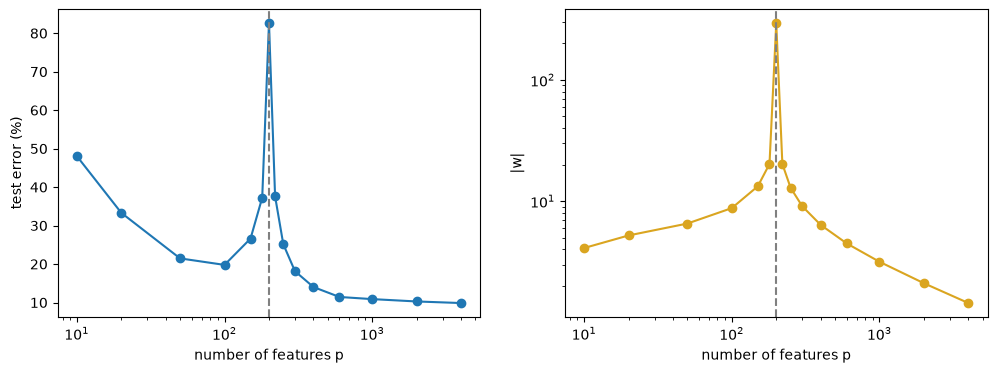

## 파트 3. 피크를 키우고 없애기

- 라벨 잡음: 다섯 장마다 한 장 (20%) 의 라벨을 다음 숫자로 바꾼다.
- 릿지: 손실 + λ‖w‖². 특징이 많을 때는 $w = F^\top (F F^\top + \lambda I)^{-1} Y$ 로 푼다 (5주차 정규화와 같은 식을 바꿔 쓴 것).
- 데이터 수: 특징 200개로 고정하고 학습 이미지 수 n 을 바꾼다.

In [ ]:
noisy = sweep_features(data, PS, N, noisy=True)
ridge = sweep_features(data, PS, N, lam=0.1)
plt.figure(figsize=(8, 4))
for res, label in [(clean, "clean"), (noisy, "20% label noise"), (ridge, "ridge lambda=0.1")]:
    plt.plot(PS, [res[p][0] for p in PS], "o-", label=label)
plt.xscale("log"); plt.axvline(N, color="gray", ls="--"); plt.xlabel("number of features p"); plt.ylabel("test error (%)"); plt.legend(); plt.show()
for name, res in [("noisy", noisy), ("ridge", ridge)]:
    print(name, {p: round(float(res[p][0])) for p in [100, 200, 4000]})

**예상 결과**

```
noisy {100: 40, 200: 87, 4000: 36}
ridge {100: 17, 200: 14, 4000: 10}
```

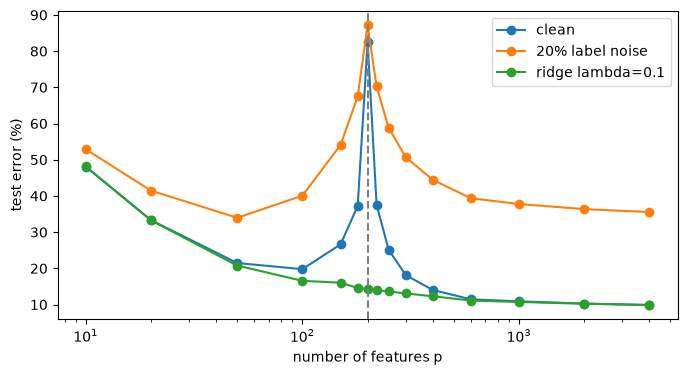

In [ ]:
def sweep_samples(data, ns, p):
    return {n: np.mean([test_error(*data, n, p, s)[0] for s in SEEDS]) for n in ns}

NS = [50, 100, 150, 180, 200, 220, 250, 300, 400, 600, 1000, 2000]
by_n = sweep_samples(data, NS, 200)
plt.plot(NS, [by_n[n] for n in NS], "s-"); plt.xscale("log"); plt.axvline(200, color="gray", ls="--")
plt.xlabel("training images n (p = 200)"); plt.ylabel("test error (%)"); plt.show()
print({n: round(float(by_n[n])) for n in [100, 200, 2000]})

**예상 결과**

```
{100: 24, 200: 83, 2000: 4}
```

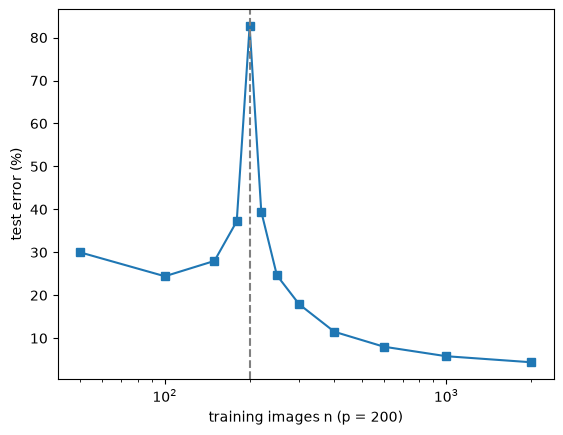

**확인 질문**
1. 파트 1 에서 `min_norm` 을 9차보다 낮은 차수 (예: 3차) 에 쓰면 오류가 난다. 왜 그런가? (힌트: $X X^\top$ 의 크기와 rank)
2. 파트 1 의 경사하강법을 모든 계수 3 에서 출발시킨 해의 크기 ‖w‖ 는 최소 노름 해보다 큰가 작은가? 새 데이터 오차는?
3. 파트 2 에서 `N` 을 400 으로 바꾸면 피크는 어디로 가는가? 실제로 돌려 확인하자.
4. 파트 2 의 `mu` (평균 빼기) 를 지우면 피크 위치가 어떻게 되나? 모든 이미지에서 0 만 내는 특징이 몇 개인지 세어 보자.
5. 파트 3 의 릿지 λ 를 0.001, 0.01, 1 로 바꿔 보자. 피크가 사라지는 가장 작은 λ 는 대략 얼마인가?

데이터 출처: E. Alpaydin, C. Kaynak (1998) Optical Recognition of Handwritten Digits, UCI Machine Learning Repository.